# Stage 1: One fibre link

**Question:** a source at node A makes entangled photon pairs. One photon is detected at A,
the other travels *L* km of fibre to node B. How many usable pairs per second arrive, and how good are they?

**Key idea: loss and noise are different things.**

* **Loss** means a photon never arrives. Fibre loses 0.2 dB/km, so after 100 km only 1% survives.
  Loss reduces the *rate*, but a lost photon creates no bad pair.
* **Noise** means a detected "pair" is not a real pair. Detectors also click on dark counts
  and background light, and sometimes two unrelated clicks fall inside the coincidence window.
  These *accidental coincidences* lower the *quality*.

**Model.** The detected pairs form a Werner state
$\rho = w\,|\Phi^+\rangle\langle\Phi^+| + (1-w)\,I/4$, where
$w = w_\text{source} \times \frac{\text{true}}{\text{true} + \text{accidental}}$.
The classical part (`qnet/physics.py`) computes $w$; PennyLane (`qnet/quantum.py`) builds the state
and measures it.

All parameter values are illustrative textbook numbers, not those of any real CERN or Geneva link.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qnet import physics as P, quantum as Q, plotstyle as S
S.apply()

In [2]:
# Parameters used throughout this notebook (change and re-run to explore)
print({k: v for k, v in P.DEFAULTS.items()})
SYNC = 10e-12                         # clock sync error between nodes (White Rabbit-like)
sigma = P.total_jitter(SYNC)          # spread of arrival-time differences
WINDOW = 3 * sigma                    # coincidence window: about 3 standard deviations
print(f"timing spread {sigma*1e12:.0f} ps, window {WINDOW*1e12:.0f} ps")

{'alpha_db_per_km': 0.2, 'pair_rate': 1000000.0, 'eta_det': 0.85, 'dark_rate': 100.0, 'det_jitter': 2e-11, 'w_source': 0.98, 'fibre_speed_km_s': 200000.0}
timing spread 30 ps, window 90 ps


## 1. The quantum state in PennyLane

First, check the building block: a Bell pair degraded to Werner weight *w*.
We read the result two ways (exact density matrix, and measured correlations $\langle XX\rangle, \langle YY\rangle, \langle ZZ\rangle$)
and compare with the formula $F = (1 + 3w)/4$.

In [3]:
link_dm = Q.make_link_circuit("dm")
link_corr = Q.make_link_circuit("corr")
print(qml_draw := __import__("pennylane").draw(link_dm)(0.9))
for w in [1.0, 0.9, 0.7]:
    xx, yy, zz = link_corr(w)
    print(f"w={w:.1f}  <XX>={float(xx):+.3f} <YY>={float(yy):+.3f} <ZZ>={float(zz):+.3f}  "
          f"F(dm)={Q.fidelity(link_dm(w)):.4f}  F(corr)={Q.fidelity_from_corr(xx,yy,zz):.4f}  "
          f"F(theory)={Q.werner_fidelity(w):.4f}")

0: ──H─╭●────────────────────────────┤ ╭DensityMatrix
1: ────╰X──DepolarizingChannel(0.07)─┤ ╰DensityMatrix
w=1.0  <XX>=+1.000 <YY>=-1.000 <ZZ>=+1.000  F(dm)=1.0000  F(corr)=1.0000  F(theory)=1.0000
w=0.9  <XX>=+0.900 <YY>=-0.900 <ZZ>=+0.900  F(dm)=0.9250  F(corr)=0.9250  F(theory)=0.9250
w=0.7  <XX>=+0.700 <YY>=-0.700 <ZZ>=+0.700  F(dm)=0.7750  F(corr)=0.7750  F(theory)=0.7750


## 2. Rate and quality against distance

We compare two detector technologies:

* **SNSPD** (superconducting nanowire, like the Single Quantum detectors in the CERN lab): 85% efficient, 100 dark counts/s, 20 ps jitter.
* **InGaAs SPAD** (cheaper avalanche photodiode): 20% efficient, 1000 dark counts/s, 200 ps jitter.

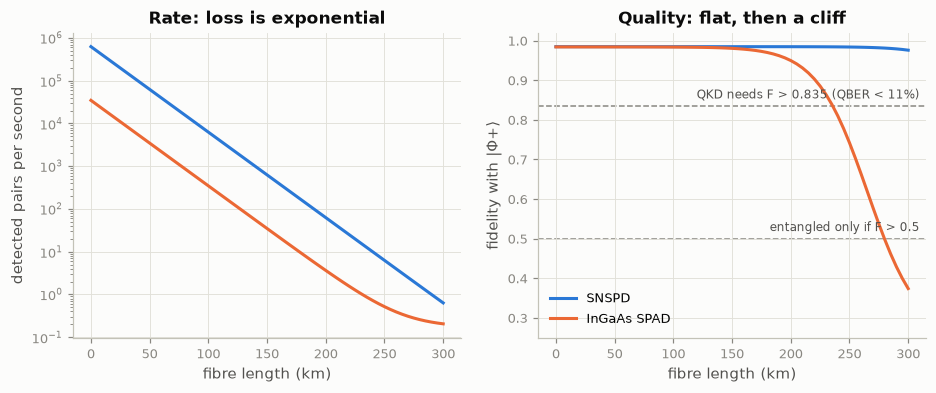

In [4]:
L = np.linspace(0, 300, 61)
detectors = {
    "SNSPD": dict(eta_det=0.85, dark_rate=100, det_jitter=20e-12),
    "InGaAs SPAD": dict(eta_det=0.20, dark_rate=1000, det_jitter=200e-12),
}
results = {}
for name, d in detectors.items():
    win = 3 * P.total_jitter(SYNC, d["det_jitter"])
    w, c = P.link_werner_weight(L, win, SYNC, **d)
    F_sim = np.array([Q.fidelity(link_dm(wi)) for wi in w])     # PennyLane
    results[name] = dict(rate=c["true"] + c["acc"], F=F_sim, w=w)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for name, r in results.items():
    ax[0].semilogy(L, r["rate"], label=name)
    ax[1].plot(L, r["F"], label=name)
ax[0].set(xlabel="fibre length (km)", ylabel="detected pairs per second", title="Rate: loss is exponential")
S.threshold(ax[1], 0.835, "QKD needs F > 0.835 (QBER < 11%)")
S.threshold(ax[1], 0.5, "entangled only if F > 0.5")
ax[1].set(xlabel="fibre length (km)", ylabel="fidelity with |Φ+⟩", title="Quality: flat, then a cliff", ylim=(0.25, 1.02))
ax[1].legend(loc="lower left")
S.save(fig, "01_rate_and_fidelity")

In [5]:
for name, r in results.items():
    ok = L[r["F"] > 0.835]
    print(f"{name:12s}: F at 0 km = {r['F'][0]:.3f}; usable for QKD up to ~{ok.max():.0f} km; "
          f"rate at 50 km = {np.interp(50, L, r['rate']):.3g} pairs/s")

SNSPD       : F at 0 km = 0.985; usable for QKD up to ~300 km; rate at 50 km = 6.26e+04 pairs/s
InGaAs SPAD : F at 0 km = 0.984; usable for QKD up to ~235 km; rate at 50 km = 3.47e+03 pairs/s


## 3. Sampling: what the detectors actually record

Measuring both photons in the Z basis many times. For a perfect pair, A and B always agree (00 or 11).
Accidental coincidences add random 01 and 10 outcomes, and those are the errors QKD has to correct.

In [6]:
samp = Q.make_link_circuit("samples_zz", shots=5000)
for name, Lkm in [("SNSPD", 50), ("InGaAs SPAD", 50), ("InGaAs SPAD", 140)]:
    w = np.interp(Lkm, L, results[name]["w"])
    s = np.asarray(samp(w))
    agree = np.mean(s[:, 0] == s[:, 1])
    print(f"{name:12s} {Lkm:3d} km: w={w:.3f}  A and B agree {agree*100:.1f}% of the time "
          f"(theory {(1+w)/2*100:.1f}%)")

SNSPD         50 km: w=0.980  A and B agree 99.2% of the time (theory 99.0%)
InGaAs SPAD   50 km: w=0.979  A and B agree 98.7% of the time (theory 98.9%)
InGaAs SPAD  140 km: w=0.976  A and B agree 99.0% of the time (theory 98.8%)


## Takeaways

* Fibre loss reduces the **rate** exponentially (10× less per 50 km) but on its own does **not** reduce quality.
* Quality stays flat until the real signal becomes comparable to the noise (dark counts × timing window).
  Then it falls off a **cliff**.
* Better detectors and **tighter timing** (a narrower window) push the cliff further out. Timing is the subject of Stage 4.